# 070 CASE 060 — Vegetation edge: Vänern's south shore

> **Experimental.** Built in the Swedish Space Data Lab (SDL 3.0) with
> [IMINT Engine](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine). Not a validated product or service, and without support.

**Question:** Where does vegetation give way to open land and water along Vänern's south shore?

**Area:** Vänern's south shore between Lidköping and Läckö (Västra Götaland), 1 August 2024.

**Partners:** Swedish Forest Agency, Stockholm University, RISE

**Data:** Copernicus Sentinel-2 L2A from [Digital Earth Sweden](https://digitalearth.se),
fetched through its openEO API.

**Licence:** The notebook is Apache-2.0 like the repository's code; its saved outputs are CC0 1.0 (see [License](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine#license)). Contains modified Copernicus Sentinel data 2024.

## Before you run

Install IMINT Engine at the commit these results were produced with, plus Jupyter and the plotting
libraries:

```bash
pip install "imint-engine[fetch,inference] @ git+https://github.com/DigitalEarthSwedenExperimentalLab/imintengine@b183e1abd4653cb843a75557b05c09915fb85904" jupyterlab folium matplotlib
```

The notebook reads Sentinel-2 from Digital Earth Sweden, so each user logs in with their own DES
account in the *Log in* cell below, either with EGI in the browser or with a DES username and
password; see [digitalearth.se](https://digitalearth.se) for access. Every data fetch goes through
that login, nothing is saved in the notebook, and without a login the fetch stops with an error.
There is no synthetic fallback: every figure comes from real Sentinel-2 data. A run takes about a minute.

## Log in to Digital Earth Sweden

In [ ]:
from getpass import getpass

import imint.fetch
import openeo
from IPython.display import clear_output

# Log in with your own Digital Earth Sweden account. Choose one:
#   "egi"      - your EGI account in the browser: open the link shown here and enter the code
#   "password" - your DES username and password, typed when asked
LOGIN_METHOD = "egi"

des = openeo.connect("https://openeo.digitalearth.se")
if LOGIN_METHOD == "password":
    user, password = input("DES username: "), getpass("DES password: ")
    if not (user and password):
        raise ValueError("enter both a DES username and a password")
    des.authenticate_basic(user, password)
    del password
else:
    des.authenticate_oidc(provider_id="egi")

# Every IMINT Engine fetch below uses this login and no other credentials on the machine
# (the pinned engine has no public parameter for a connection yet).
imint.fetch._connect = lambda token=None, token_path=None: des
clear_output()  # keep the typed username and the login link out of a saved notebook
print("Logged in to Digital Earth Sweden.")


## 1. Method

```
AOI + date → fetch_des_data → VegetationEdgeAnalyzer → water / non-vegetated / vegetated map + edge centreline
```

## 2. Area and data

The map is interactive when the notebook runs in Jupyter; GitHub's viewer shows only a placeholder for it.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import folium

from imint.fetch import fetch_des_data


def load_scene(date, aoi, max_cloud=0.3):
    """Fetch one Sentinel-2 L2A scene from Digital Earth Sweden with your login (no fallback)."""
    scene = fetch_des_data(date=date, coords=aoi, cloud_threshold=max_cloud)
    nodata = np.all(np.stack([a == 0 for a in scene.bands.values()]), axis=0)
    if nodata.mean() > 0.01:  # the archive sometimes holds only part of a scene
        raise ValueError(f"{date}: {nodata.mean():.0%} of the area has no data in this DES scene; use another date")
    land = np.isin(scene.scl, [4, 5])  # cloud-free vegetation and bare soil
    if land.any():
        empty = [b for b, a in scene.bands.items() if (a[land] == 0).mean() > 0.05]
        if empty:  # some archived scenes have bands missing; never analyse them
            raise ValueError(f"{date}: bands {empty} are empty over land in this DES scene; use another date")
    h, w = scene.rgb.shape[:2]
    print(f"{date}: {len(scene.bands)} bands, {h} x {w} px at 10 m, "
          f"cloud and shadow {scene.cloud_fraction:.1%} (SCL), CRS {scene.geo.crs}")
    return scene

AOI = {"west": 13.15, "south": 58.50, "east": 13.35, "north": 58.60}  # Lidköping–Läckö, Vänern
DATE = "2024-08-01"

scene = load_scene(DATE, AOI)

    Cloud fraction: 0.0%
2024-08-01: 11 bands, 1145 x 1194 px at 10 m, cloud and shadow 0.0% (SCL), CRS EPSG:3006


In [3]:
center = [(AOI["south"] + AOI["north"]) / 2, (AOI["west"] + AOI["east"]) / 2]
m = folium.Map(location=center, zoom_start=11, tiles="OpenStreetMap")
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri, Maxar, Earthstar Geographics", name="Satellite basemap",
).add_to(m)
folium.Rectangle(
    bounds=[[AOI["south"], AOI["west"]], [AOI["north"], AOI["east"]]],
    color="#00aa00", weight=2, fill=False, popup="AOI",
).add_to(m)
folium.LayerControl().add_to(m)
m

## 3. Run the vegetation-edge analyzer

In [4]:
from imint.analyzers.vegetation_edge import VegetationEdgeAnalyzer

edge = VegetationEdgeAnalyzer({}).run(rgb=scene.rgb, bands=scene.bands, date=DATE, coords=AOI,
                                      output_dir="outputs/060", scl=scene.scl, geo=scene.geo)
print(edge.summary())
ve = edge.outputs
print(f"vegetated fraction: {ve['vegetation_fraction']:.1%}, edge segments: {ve['n_contours']}")
for name, frac in ve["class_fractions"].items():
    print(f"  {name}: {frac:.1%}")

[vegetation_edge] OK — outputs: segmentation_map, vegetation_edge_mask, vegetation_fraction, class_fractions, ndvi, n_contours
vegetated fraction: 25.3%, edge segments: 78
  water: 69.4%
  non_vegetated: 5.3%
  vegetated: 25.3%


## 4. Results

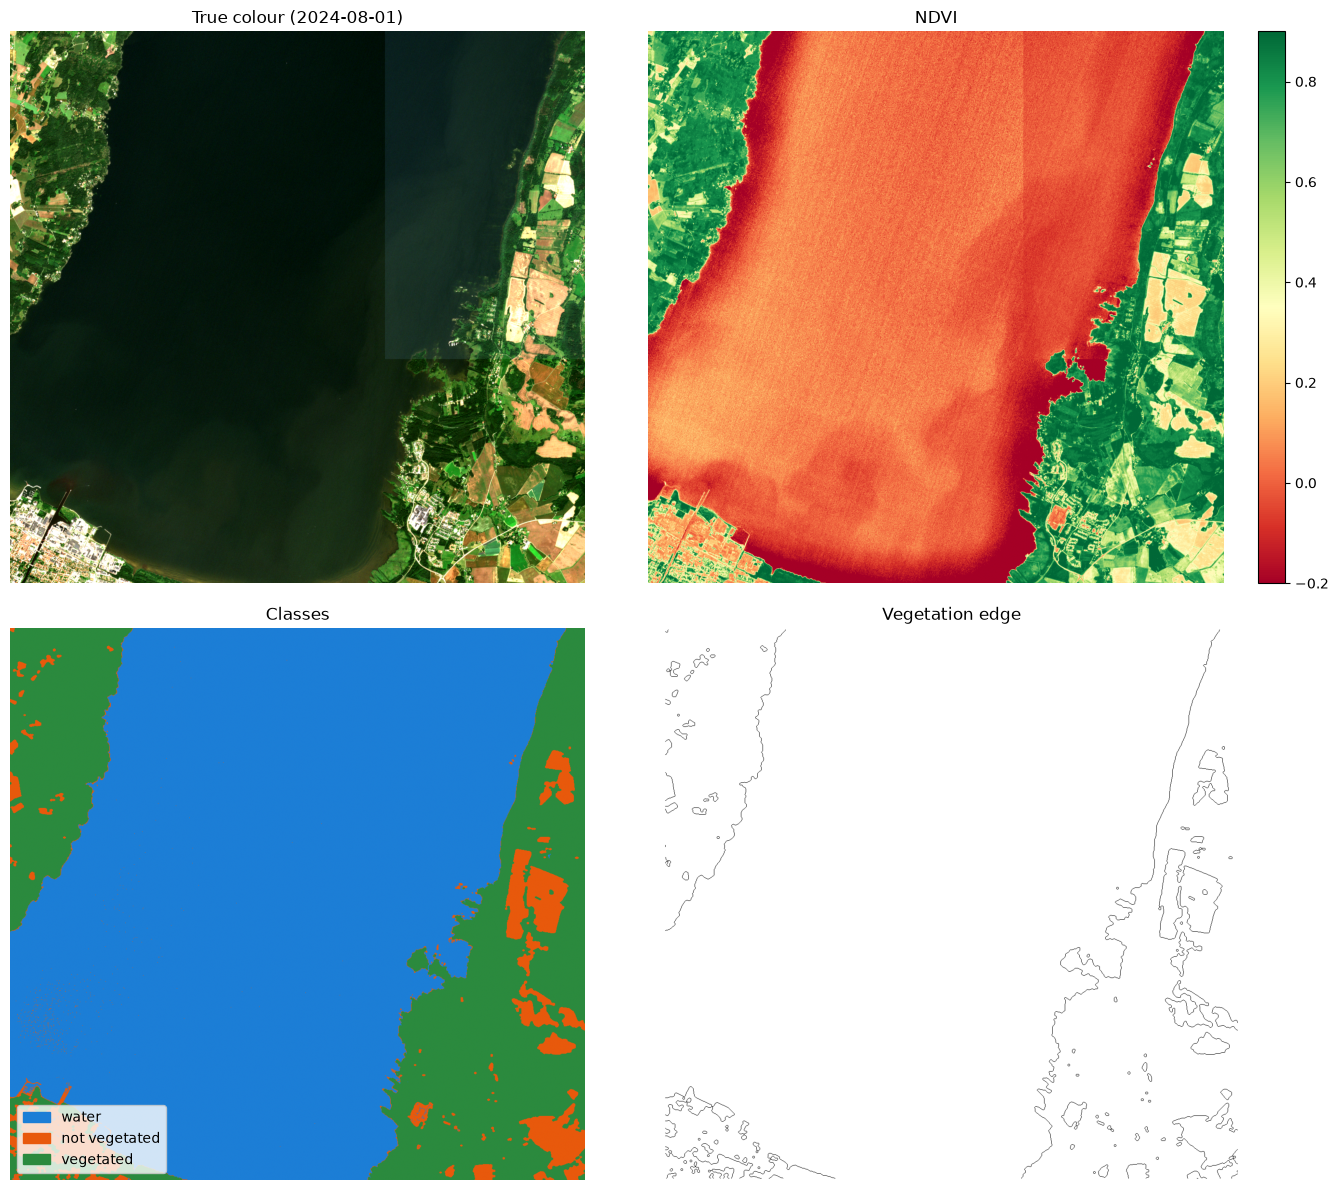

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes[0, 0].imshow(scene.rgb); axes[0, 0].set_title(f"True colour ({DATE})")
im = axes[0, 1].imshow(ve["ndvi"], cmap="RdYlGn", vmin=-0.2, vmax=0.9); axes[0, 1].set_title("NDVI")
fig.colorbar(im, ax=axes[0, 1], fraction=0.046)
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
class_colours = ["#1c7ed6", "#e8590c", "#2b8a3e"]  # 0 water, 1 not vegetated, 2 vegetated
axes[1, 0].imshow(ve["segmentation_map"], cmap=ListedColormap(class_colours), vmin=0, vmax=2)
axes[1, 0].legend(handles=[Patch(color=c, label=l) for c, l in
                           zip(class_colours, ["water", "not vegetated", "vegetated"])], loc="lower left")
axes[1, 0].set_title("Classes")
axes[1, 1].imshow(ve["vegetation_edge_mask"], cmap="binary"); axes[1, 1].set_title("Vegetation edge")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Interpretation

The edge map follows the lake shore, field boundaries and clearings. Along Vänern the vegetation edge
moves with the water level and with overgrowth of open shore meadows; compared over several years it
can show both, while a single date describes one moment.

**Links:** [`imint/analyzers/vegetation_edge.py`](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine/blob/b183e1a/imint/analyzers/vegetation_edge.py)

## Provenance

The saved outputs were produced by running this notebook top to bottom against IMINT Engine commit [`b183e1a`](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine/commit/b183e1abd4653cb843a75557b05c09915fb85904) with data from Digital Earth Sweden. Dates are acquisition dates, chosen among the scenes DES holds by the cloud fraction over the area in the scene classification (SCL).